# Лабораторная работа №4

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 4.1
### Вариант 18
```txt
y'' - (x + 1)y'/x - 2(x - 1)y/x = 0
y(1) = 1
y'(1) = 1
1 <= x <= 2
h = 0.1

Точное решение
y = 5 * exp(2x - 2) / 9 + (3x + 1) * exp(1 - x) / 9
```

In [2]:
x_start = 1.0
x_end = 2.0
h = 0.1

y0 = 1.0
z0 = 1.0


def f_system(x, Y):
    y, z = Y
    dy_dx = z
    dz_dx = ((x + 1) / x) * z + 2 * ((x - 1) / x) * y
    return np.array([dy_dx, dz_dx])


def exact_solution(x):
    term1 = 5 * np.exp(2 * x - 2) / 9
    term2 = (3 * x + 1) * np.exp(1 - x) / 9
    return term1 + term2

In [3]:
def euler_method(f, x0, y0, h, x_end):
    n_steps = int(np.round((x_end - x0) / h))
    x = np.linspace(x0, x0 + n_steps * h, n_steps + 1)
    y = np.zeros((n_steps + 1, len(y0)))
    y[0] = y0
    
    for i in range(n_steps):
        y[i+1] = y[i] + h * f(x[i], y[i])
    return x, y


def runge_kutta_4(f, x0, y0, h, x_end):
    n_steps = int(np.round((x_end - x0) / h))
    x = np.linspace(x0, x0 + n_steps * h, n_steps + 1)
    y = np.zeros((n_steps + 1, len(y0)))
    y[0] = y0
    
    for i in range(n_steps):
        k1 = h * f(x[i], y[i])
        k2 = h * f(x[i] + h/2, y[i] + k1/2)
        k3 = h * f(x[i] + h/2, y[i] + k2/2)
        k4 = h * f(x[i] + h, y[i] + k3)
        y[i+1] = y[i] + (k1 + 2*k2 + 2*k3 + k4) / 6
    return x, y


def adams_bashforth_4(f, x0, y0, h, x_end):
    n_steps = int(np.round((x_end - x0) / h))
    x = np.linspace(x0, x0 + n_steps * h, n_steps + 1)
    y = np.zeros((n_steps + 1, len(y0)))
    y[0] = y0
    
    for i in range(min(3, n_steps)):
        k1 = h * f(x[i], y[i])
        k2 = h * f(x[i] + h/2, y[i] + k1/2)
        k3 = h * f(x[i] + h/2, y[i] + k2/2)
        k4 = h * f(x[i] + h, y[i] + k3)
        y[i+1] = y[i] + (k1 + 2*k2 + 2*k3 + k4) / 6
        
    for i in range(3, n_steps):
        f_n = f(x[i], y[i])
        f_n1 = f(x[i-1], y[i-1])
        f_n2 = f(x[i-2], y[i-2])
        f_n3 = f(x[i-3], y[i-3])
        
        y[i+1] = y[i] + (h/24) * (55*f_n - 59*f_n1 + 37*f_n2 - 9*f_n3)
        
    return x, y

Максимальная погрешность (h=0.1):
Метод Эйлера: 6.76e-01
Метод Рунге-Кутты 4: 9.81e-05
Метод Адамса 4: 2.38e-03


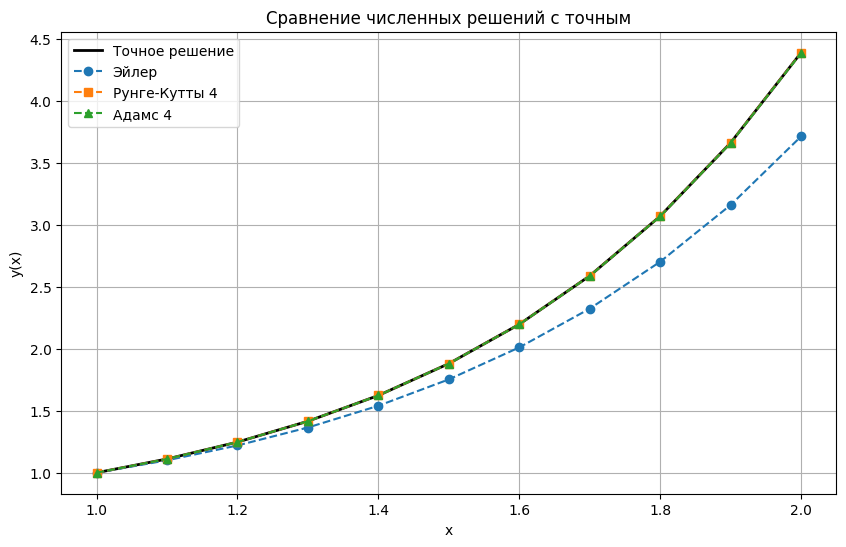

In [4]:
Y0 = np.array([y0, z0])

x_euler, y_euler = euler_method(f_system, x_start, Y0, h, x_end)
x_rk4, y_rk4 = runge_kutta_4(f_system, x_start, Y0, h, x_end)
x_adams, y_adams = adams_bashforth_4(f_system, x_start, Y0, h, x_end)

y_exact_vals = exact_solution(x_rk4)

err_euler = np.max(np.abs(y_euler[:, 0] - y_exact_vals))
err_rk4 = np.max(np.abs(y_rk4[:, 0] - y_exact_vals))
err_adams = np.max(np.abs(y_adams[:, 0] - y_exact_vals))

print(f"Максимальная погрешность (h={h}):")
print(f"Метод Эйлера: {err_euler:.2e}")
print(f"Метод Рунге-Кутты 4: {err_rk4:.2e}")
print(f"Метод Адамса 4: {err_adams:.2e}")

plt.figure(figsize=(10, 6))
plt.plot(x_rk4, y_exact_vals, 'k-', linewidth=2, label='Точное решение')
plt.plot(x_euler, y_euler[:, 0], 'o--', label='Эйлер')
plt.plot(x_rk4, y_rk4[:, 0], 's--', label='Рунге-Кутты 4')
plt.plot(x_adams, y_adams[:, 0], '^--', label='Адамс 4')
plt.title('Сравнение численных решений с точным')
plt.xlabel('x')
plt.ylabel('y(x)')
plt.legend()
plt.grid(True)
plt.show()

In [5]:
def estimate_error_runge(order, method_func):
    _, y_h = method_func(f_system, x_start, Y0, h, x_end)
    x_h2, y_h2 = method_func(f_system, x_start, Y0, h/2, x_end)
    
    y_h2_on_h_grid = y_h2[::2]
    
    diff = np.abs(y_h[:, 0] - y_h2_on_h_grid[:, 0])
    runge_error = diff / (2**order - 1)
    
    return np.max(runge_error)

print("Оценка погрешности методом Рунге-Ромберга:")
print(f"Эйлер (p=1): {estimate_error_runge(1, euler_method):.4e}")
print(f"Рунге-Кутты (p=4): {estimate_error_runge(4, runge_kutta_4):.4e}")
print(f"Адамс (p=4): {estimate_error_runge(4, adams_bashforth_4):.4e}")

Оценка погрешности методом Рунге-Ромберга:
Эйлер (p=1): 3.0215e-01
Рунге-Кутты (p=4): 6.0977e-06
Адамс (p=4): 1.4489e-04


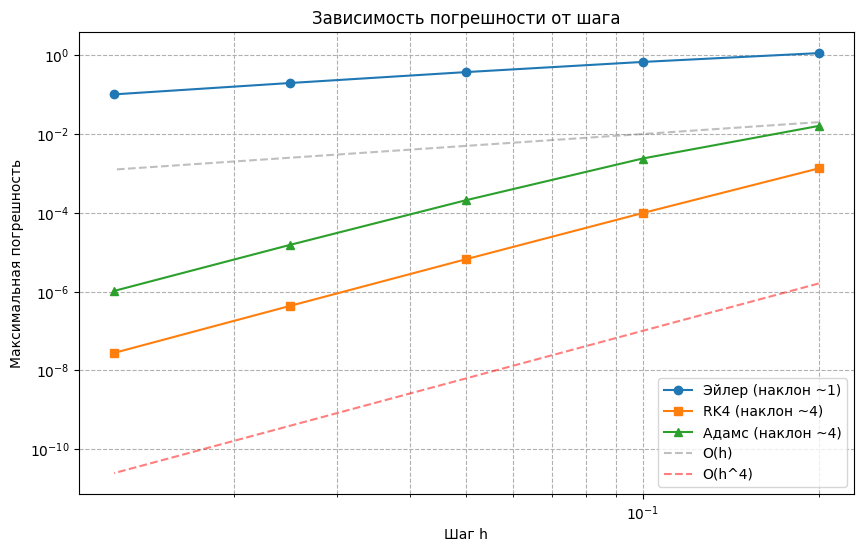

In [6]:
steps = [0.2, 0.1, 0.05, 0.025, 0.0125]
errors_exact = {'Euler': [], 'RK4': [], 'Adams': []}

for h_val in steps:
    _, y_e = euler_method(f_system, x_start, Y0, h_val, x_end)
    _, y_r = runge_kutta_4(f_system, x_start, Y0, h_val, x_end)
    _, y_a = adams_bashforth_4(f_system, x_start, Y0, h_val, x_end)
    
    x_curr = np.linspace(x_start, x_end, len(y_e))
    y_ex = exact_solution(x_curr)
    
    errors_exact['Euler'].append(np.max(np.abs(y_e[:,0] - y_ex)))
    errors_exact['RK4'].append(np.max(np.abs(y_r[:,0] - y_ex)))
    errors_exact['Adams'].append(np.max(np.abs(y_a[:,0] - y_ex)))

plt.figure(figsize=(10, 6))
plt.loglog(steps, errors_exact['Euler'], 'o-', label='Эйлер (наклон ~1)')
plt.loglog(steps, errors_exact['RK4'], 's-', label='RK4 (наклон ~4)')
plt.loglog(steps, errors_exact['Adams'], '^-', label='Адамс (наклон ~4)')

ref_h = np.array(steps)
plt.loglog(ref_h, 0.1 * ref_h, '--', color='gray', alpha=0.5, label='O(h)')
plt.loglog(ref_h, 0.001 * ref_h**4, '--', color='red', alpha=0.5, label='O(h^4)')

plt.title('Зависимость погрешности от шага')
plt.xlabel('Шаг h')
plt.ylabel('Максимальная погрешность')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

## 4.2

### Вариант 18
```text
x * y'' - (x + 1)y'- 2(x - 1)y=0
y'(0) = 4
y'(1) - 2y(1) = -9 * exp(-1)

Точное решение
y(x)= exp(2x) + (3x+1) exp(-x)

```

In [7]:
x_start = 0.1
x_end = 1.0
h = 0.05       

def exact_solution(x):
    return np.exp(2*x) + (3*x + 1) * np.exp(-x)


def exact_derivative(x):
    return 2*np.exp(2*x) + 3*np.exp(-x) - (3*x + 1)*np.exp(-x)

In [8]:
def f_system(x, Y):
    y, z = Y
    dy_dx = z
    dz_dx = ((x + 1) / x) * z + 2 * ((x - 1) / x) * y
    return np.array([dy_dx, dz_dx])


def runge_kutta_4(f, x0, y0, h, x_end):
    n_steps = int(np.round((x_end - x0) / h))
    x = np.linspace(x0, x0 + n_steps * h, n_steps + 1)
    y = np.zeros((n_steps + 1, len(y0)))
    y[0] = y0
    
    for i in range(n_steps):
        k1 = h * f(x[i], y[i])
        k2 = h * f(x[i] + h/2, y[i] + k1/2)
        k3 = h * f(x[i] + h/2, y[i] + k2/2)
        k4 = h * f(x[i] + h, y[i] + k3)
        y[i+1] = y[i] + (k1 + 2*k2 + 2*k3 + k4) / 6
    return x, y

In [9]:
def shooting_method(f, x0, x1, y0, target_bc_val, h, tol=1e-7):
    def boundary_residual(z0):
        _, sol_y = runge_kutta_4(f, x0, [y0, z0], h, x1)
        y_end = sol_y[-1, 0]
        z_end = sol_y[-1, 1]
        return (z_end - 2*y_end) - target_bc_val

    a, b = 0.0, 10.0
    
    if boundary_residual(a) * boundary_residual(b) > 0:
        raise ValueError("Корень не найден в заданном интервале.")
        
    while (b - a) / 2.0 > tol:
        midpoint = (a + b) / 2.0
        if boundary_residual(midpoint) == 0:
            a = midpoint
            break
        elif boundary_residual(a) * boundary_residual(midpoint) < 0:
            b = midpoint
        else:
            a = midpoint
            
    z0_opt = (a + b) / 2.0
    
    x_vals, y_vals = runge_kutta_4(f, x0, [y0, z0_opt], h, x1)
    
    return x_vals, y_vals[:, 0], z0_opt

y_start_val = exact_solution(x_start)
target_bc = -9 * np.exp(-1)

x_shoot, y_shoot, z0_found = shooting_method(f_system, x_start, x_end, y_start_val, target_bc, h)
print(f"Найденный y'({x_start}) = {z0_found:.5f}")

Найденный y'(0.1) = 3.98106


In [10]:
def finite_difference_method(x0, x1, y_left, bc_right_val, h):
    N = int(np.round((x1 - x0) / h))
    x = np.linspace(x0, x1, N + 1)
    
    A = np.zeros((N + 1, N + 1))
    d = np.zeros(N + 1)
    
    A[0, 0] = 1
    d[0] = y_left
    
    for i in range(1, N):
        xi = x[i]
        p_i = (xi + 1) / xi
        q_i = 2 * (xi - 1) / xi
        
        A[i, i-1] = 1 / h**2 + p_i / (2 * h)
        A[i, i] = -2 / h**2 - q_i
        A[i, i+1] = 1 / h**2 - p_i / (2 * h)
        d[i] = 0
        
    A[N, N-1] = -1 / h
    A[N, N] = 1 / h - 2
    d[N] = bc_right_val
    
    y = np.linalg.solve(A, d)
    return x, y

x_fd, y_fd = finite_difference_method(x_start, x_end, y_start_val, target_bc, h)

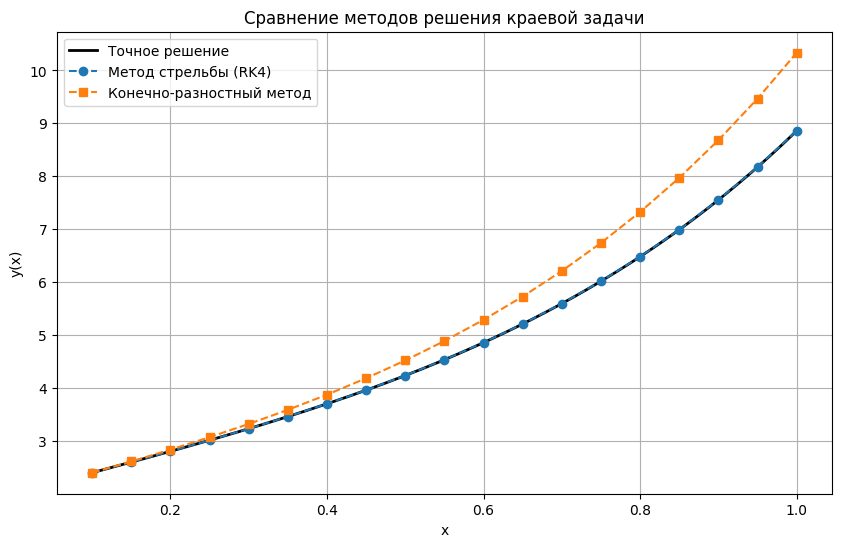

Оценка погрешности (Рунге-Ромберг):
Метод стрельбы:  1.7926e-06
Конечно-разностный: 2.6842e-01

Фактическая погрешность:
Метод стрельбы:  2.8923e-05
Конечно-разностный: 1.4750e+00


In [11]:
x_exact = np.linspace(x_start, x_end, 200)
plt.figure(figsize=(10, 6))
plt.plot(x_exact, exact_solution(x_exact), 'k-', linewidth=2, label='Точное решение')
plt.plot(x_shoot, y_shoot, 'o--', label='Метод стрельбы (RK4)')
plt.plot(x_fd, y_fd, 's--', label='Конечно-разностный метод')
plt.title('Сравнение методов решения краевой задачи')
plt.xlabel('x')
plt.ylabel('y(x)')
plt.legend()
plt.grid(True)
plt.show()


_, y_shoot_h = shooting_method(f_system, x_start, x_end, y_start_val, target_bc, h)[:2]
_, y_shoot_h2 = shooting_method(f_system, x_start, x_end, y_start_val, target_bc, h/2)[:2]
err_runge_shoot = np.max(np.abs(y_shoot_h - y_shoot_h2[::2])) / (2**4 - 1)

_, y_fd_h = finite_difference_method(x_start, x_end, y_start_val, target_bc, h)
_, y_fd_h2 = finite_difference_method(x_start, x_end, y_start_val, target_bc, h/2)
err_runge_fd = np.max(np.abs(y_fd_h - y_fd_h2[::2])) / (2**2 - 1)

print("Оценка погрешности (Рунге-Ромберг):")
print(f"Метод стрельбы:  {err_runge_shoot:.4e}")
print(f"Конечно-разностный: {err_runge_fd:.4e}")

print("\nФактическая погрешность:")
print(f"Метод стрельбы:  {np.max(np.abs(y_shoot - exact_solution(x_shoot))):.4e}")
print(f"Конечно-разностный: {np.max(np.abs(y_fd - exact_solution(x_fd))):.4e}")